# EDA Course Project: Bank Marketing Dataset Analysis
**Name:** Jai Goel
**Register Number:** 23BDS0191

---
# PHASE I: Exploratory Data Analysis

## 1. Loading the Dataset

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/bank-full.csv"
df = pd.read_csv(url, sep=';')

print("Dataset Loaded Successfully!")
display(df.head())
df.info()

Dataset Loaded Successfully!


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

## 2. Basic Statistical Analysis

In [61]:
print("--- Numerical Summary Statistics ---")
display(df.describe())

print("\n--- Categorical Summary Statistics ---")
display(df.describe(include=['O']))

print("\n--- Target Variable (y) Distribution ---")
print(df['y'].value_counts())

--- Numerical Summary Statistics ---


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000



--- Categorical Summary Statistics ---


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548



--- Target Variable (y) Distribution ---
y
no     36548
yes     4640
Name: count, dtype: int64


## 3. Handling Missing Data

In [62]:
df = df.replace('unknown', np.nan)

print("--- Missing Values Before Handling ---")
print(df.isnull().sum())

for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna(df.groupby('y')[col].transform(lambda x: x.mode().iloc[0] if not x.mode().empty else 'unknown'))

print("\n--- Missing Values After Imputation ---")
print(df.isnull().sum().sum())

--- Missing Values Before Handling ---
age                  0
job                330
marital             80
education         1731
default           8597
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64

--- Missing Values After Imputation ---
0


## 4. Data Cleaning

In [63]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates()

for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.strip()

print("Data Cleaning Completed.")
display(df.head())

Number of duplicate rows: 14
Data Cleaning Completed.


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 5. Data Transformation

In [64]:
from sklearn.preprocessing import LabelEncoder

df['duration_min'] = df['duration'] / 60

le = LabelEncoder()
df['y_Encoded'] = le.fit_transform(df['y'])

education_order = {'illiterate': 0, 'basic.4y': 1, 'basic.6y': 2, 'basic.9y': 3,
                    'high.school': 4, 'professional.course': 5, 'university.degree': 6}
df['education_Encoded'] = df['education'].map(education_order)

df['job_Encoded'] = LabelEncoder().fit_transform(df['job'])
df['marital_Encoded'] = LabelEncoder().fit_transform(df['marital'])
df['contact_Encoded'] = LabelEncoder().fit_transform(df['contact'])
df['poutcome_Encoded'] = LabelEncoder().fit_transform(df['poutcome'])

print("Data Transformation Completed.")
display(df.head())

Data Transformation Completed.


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,euribor3m,nr.employed,y,duration_min,y_Encoded,education_Encoded,job_Encoded,marital_Encoded,contact_Encoded,poutcome_Encoded
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,4.857,5191.0,no,4.350000,0,1,3,1,1,1
1,57,services,married,high.school,no,no,no,telephone,may,mon,...,4.857,5191.0,no,2.483333,0,4,7,1,1,1
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,4.857,5191.0,no,3.766667,0,4,7,1,1,1
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,4.857,5191.0,no,2.516667,0,2,0,1,1,1
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,4.857,5191.0,no,5.116667,0,4,7,1,1,1


## 6. Univariate Analysis

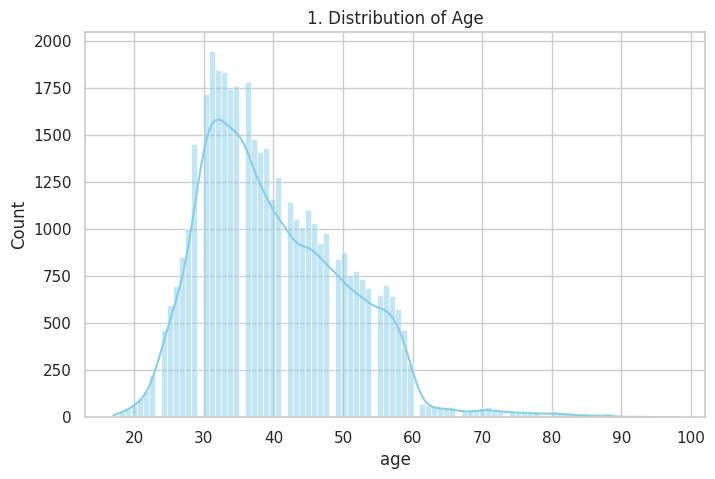

In [65]:
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], kde=True, color='skyblue')
plt.title('1. Distribution of Age')
plt.show()

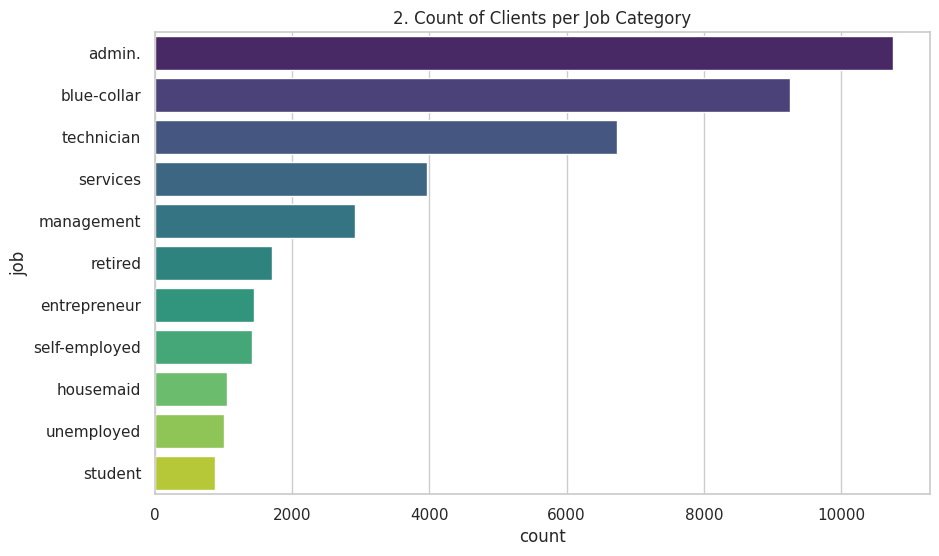

In [66]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='job', order=df['job'].value_counts().index, palette='viridis')
plt.title('2. Count of Clients per Job Category')
plt.show()

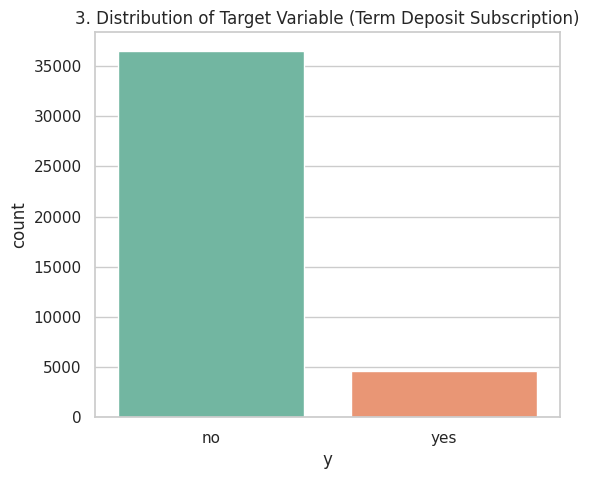

In [67]:
plt.figure(figsize=(6, 5))
sns.countplot(data=df, x='y', palette='Set2')
plt.title('3. Distribution of Target Variable (Term Deposit Subscription)')
plt.show()

## 7. Bivariate Analysis

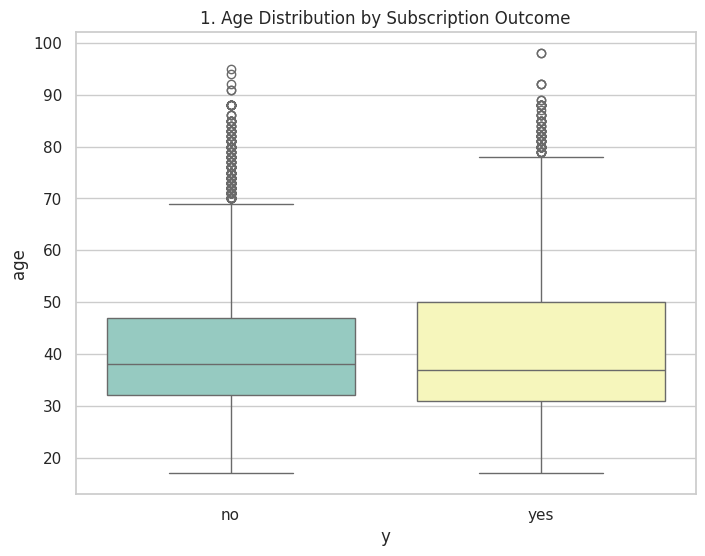

In [68]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='y', y='age', palette='Set3')
plt.title('1. Age Distribution by Subscription Outcome')
plt.show()

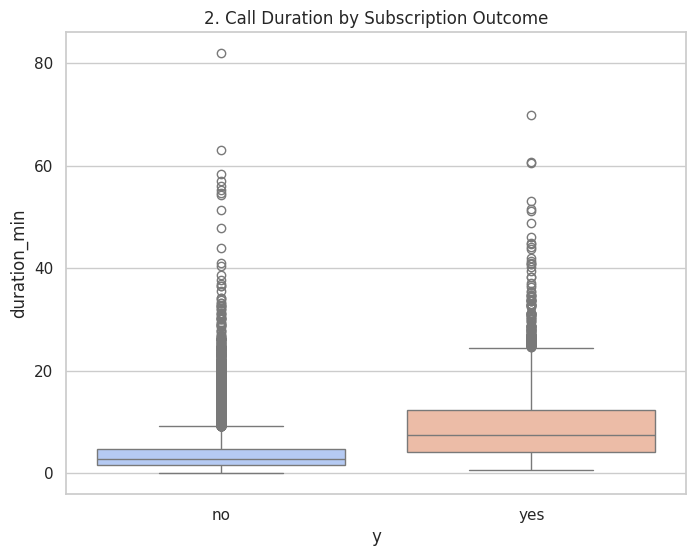

In [69]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='y', y='duration_min', palette='coolwarm')
plt.title('2. Call Duration by Subscription Outcome')
plt.show()

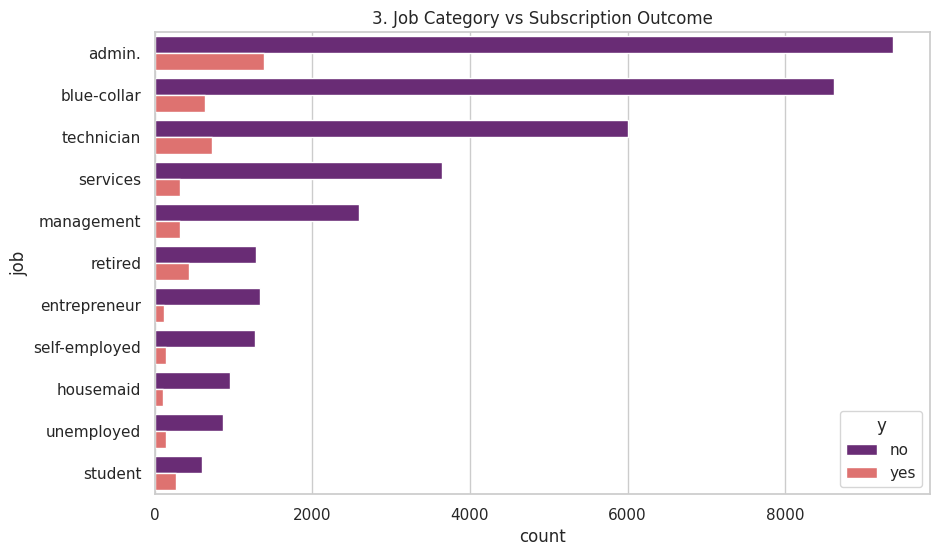

In [70]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='job', hue='y', order=df['job'].value_counts().index, palette='magma')
plt.title('3. Job Category vs Subscription Outcome')
plt.show()

## 8. Multivariate Analysis

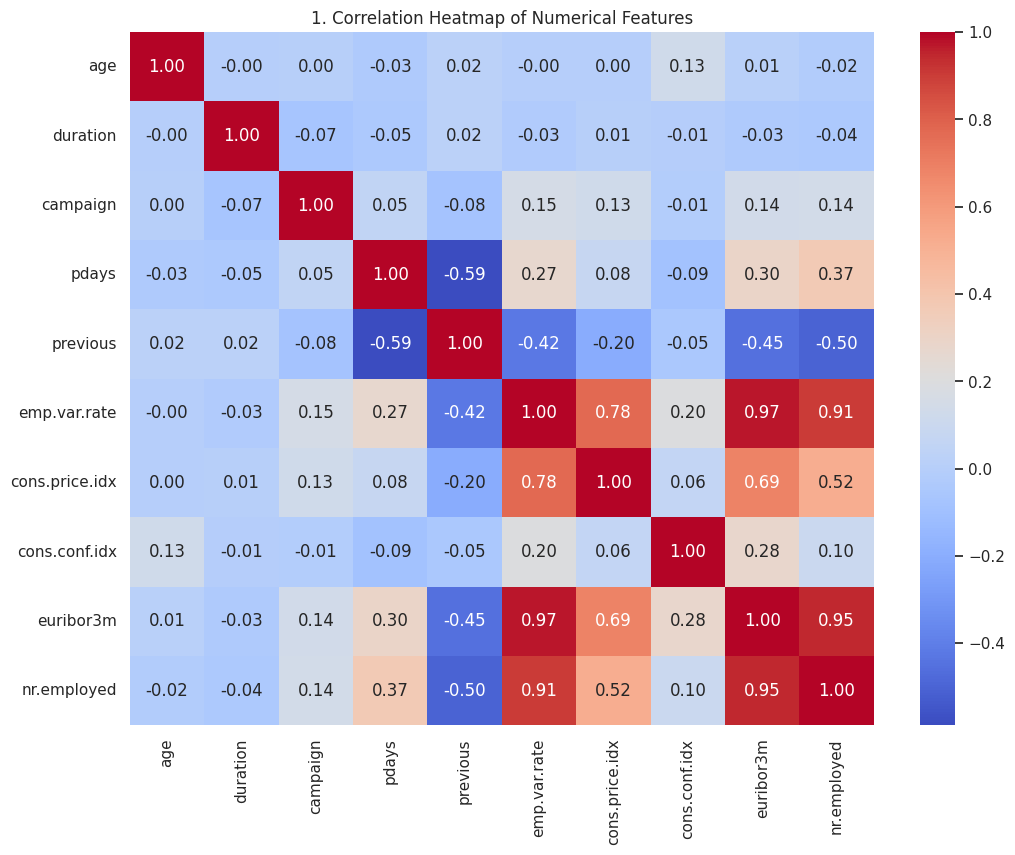

In [71]:
numeric_cols_p1 = ['age', 'duration', 'campaign', 'pdays', 'previous',
                    'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

plt.figure(figsize=(12, 9))
sns.heatmap(df[numeric_cols_p1].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('1. Correlation Heatmap of Numerical Features')
plt.show()

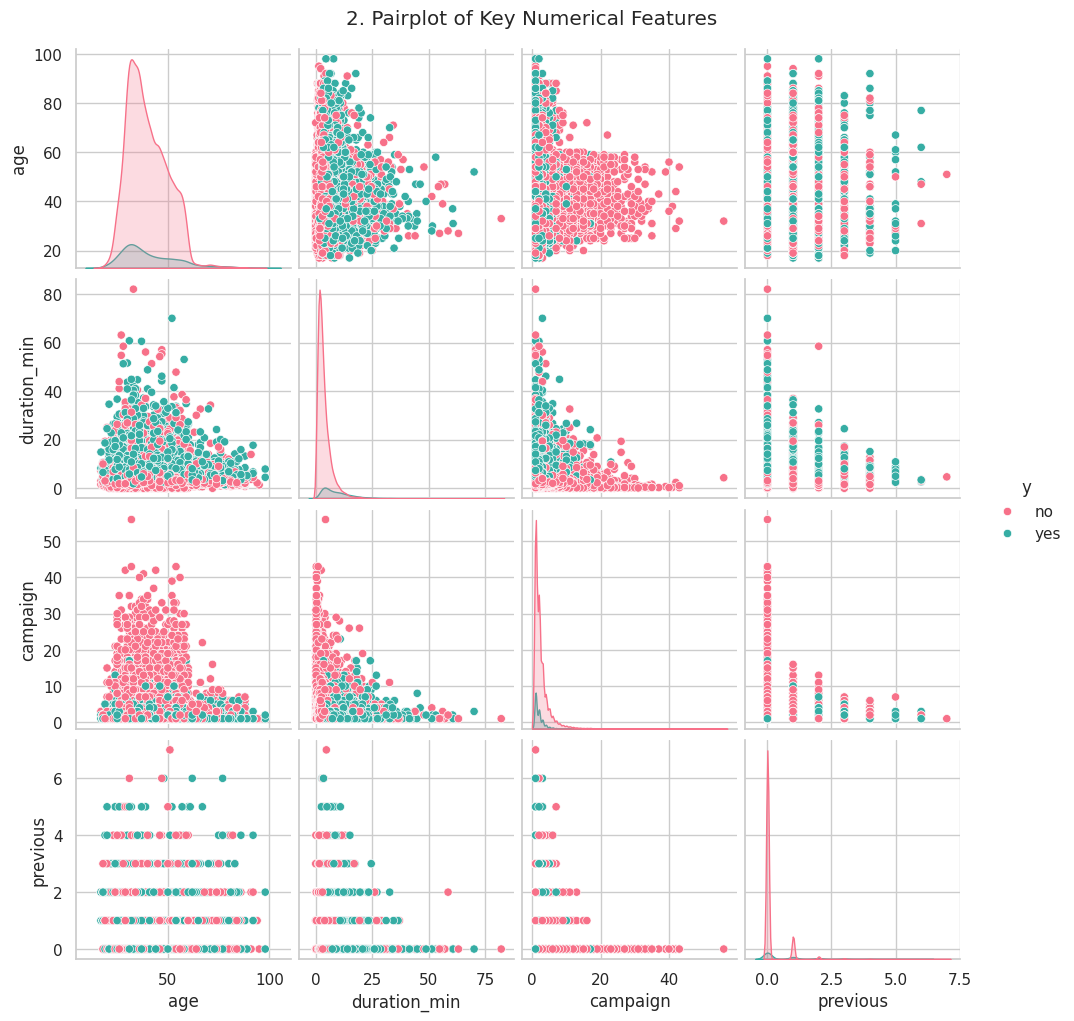

In [72]:
sns.pairplot(df[['age', 'duration_min', 'campaign', 'previous', 'y']], hue='y', palette='husl')
plt.suptitle('2. Pairplot of Key Numerical Features', y=1.02)
plt.show()

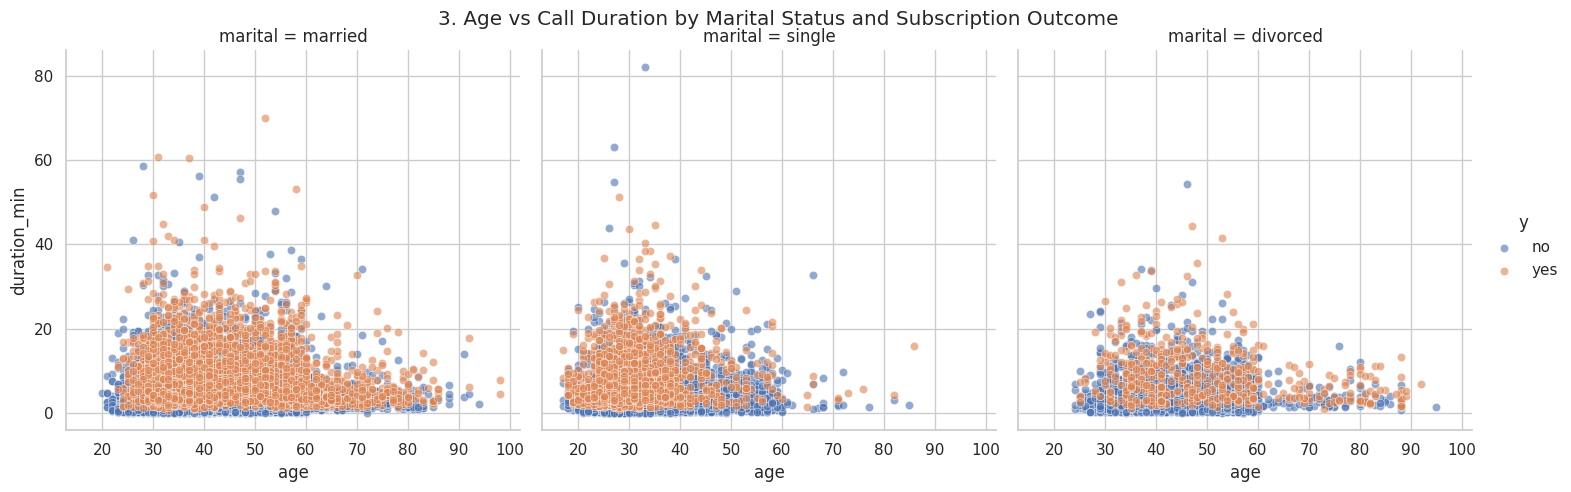

In [73]:
g = sns.FacetGrid(df, col='marital', hue='y', height=5)
g.map(sns.scatterplot, 'age', 'duration_min', alpha=.6)
g.add_legend()
plt.subplots_adjust(top=0.9)
g.fig.suptitle('3. Age vs Call Duration by Marital Status and Subscription Outcome')
plt.show()

---
# PHASE II: Statistical Analysis (1D, 2D & 3D) and Clustering (K-Means & Hierarchical)

## 1. One-Dimensional (1D) Statistical Analysis

In [74]:
from scipy import stats

numeric_cols = ['age', 'duration', 'campaign', 'pdays', 'previous',
                 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

stats_1d = pd.DataFrame({
    'Mean': df[numeric_cols].mean(),
    'Median': df[numeric_cols].median(),
    'Mode': df[numeric_cols].mode().iloc[0],
    'Std Dev': df[numeric_cols].std(),
    'Variance': df[numeric_cols].var(),
    'Skewness': df[numeric_cols].skew(),
    'Kurtosis': df[numeric_cols].kurt(),
    'Range': df[numeric_cols].max() - df[numeric_cols].min(),
    'Min': df[numeric_cols].min(),
    'Max': df[numeric_cols].max()
}).round(2)

display(stats_1d)

,Mean,Median,Mode,Std Dev,Variance,Skewness,Kurtosis,Range,Min,Max
age,40.02,38.00,31.00,10.42,108.59,0.78,0.79,81.00,17.00,98.00
duration,258.32,180.00,85.00,259.31,67241.19,3.26,20.24,4918.00,0.00,4918.00
campaign,2.57,2.00,1.00,2.77,7.67,4.76,36.97,55.00,1.00,56.00
pdays,962.46,999.00,999.00,186.94,34947.11,-4.92,22.22,999.00,0.00,999.00
previous,0.17,0.00,0.00,0.49,0.25,3.83,20.10,7.00,0.00,7.00
emp.var.rate,0.08,1.10,1.40,1.57,2.47,-0.72,-1.06,4.80,-3.40,1.40
cons.price.idx,93.58,93.75,93.99,0.58,0.34,-0.23,-0.83,2.57,92.20,94.77
cons.conf.idx,-40.50,-41.80,-36.40,4.63,21.42,0.30,-0.36,23.90,-50.80,-26.90
euribor3m,3.62,4.86,4.86,1.73,3.01,-0.71,-1.41,4.41,0.63,5.04
nr.employed,5167.03,5191.00,5228.10,72.25,5220.41,-1.04,-0.00,264.50,4963.60,5228.10


In [75]:
print(f"{'Feature':<18}{'W-Statistic':<15}{'p-value':<15}{'Normal? (alpha=0.05)'}")
print("-" * 63)
for col in numeric_cols:
    sample = df[col].dropna().sample(min(5000, len(df)), random_state=42)
    stat, p = stats.shapiro(sample)
    verdict = "Yes" if p > 0.05 else "No"
    print(f"{col:<18}{stat:<15.4f}{p:<15.4g}{verdict}")

Feature           W-Statistic    p-value        Normal? (alpha=0.05)
---------------------------------------------------------------
age               0.9584         1.322e-35      No
duration          0.7382         8.785e-67      No
campaign          0.5542         1.088e-77      No
pdays             0.1863         4.954e-91      No
previous          0.3975         3.115e-84      No
emp.var.rate      0.7621         6.514e-65      No
cons.price.idx    0.9323         7.314e-43      No
cons.conf.idx     0.9226         5.269e-45      No
euribor3m         0.6861         2.097e-70      No
nr.employed       0.7919         2.404e-62      No


In [76]:
outlier_summary = {}
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary[col] = n_outliers

outlier_df = pd.DataFrame.from_dict(outlier_summary, orient='index', columns=['Outlier Count'])
outlier_df['% of Data'] = (outlier_df['Outlier Count'] / len(df) * 100).round(2)
display(outlier_df.sort_values('Outlier Count', ascending=False))

,Outlier Count,% of Data
previous,5625,13.66
duration,2963,7.20
campaign,2406,5.84
pdays,1515,3.68
age,468,1.14
cons.conf.idx,446,1.08
emp.var.rate,0,0.00
cons.price.idx,0,0.00
euribor3m,0,0.00
nr.employed,0,0.00


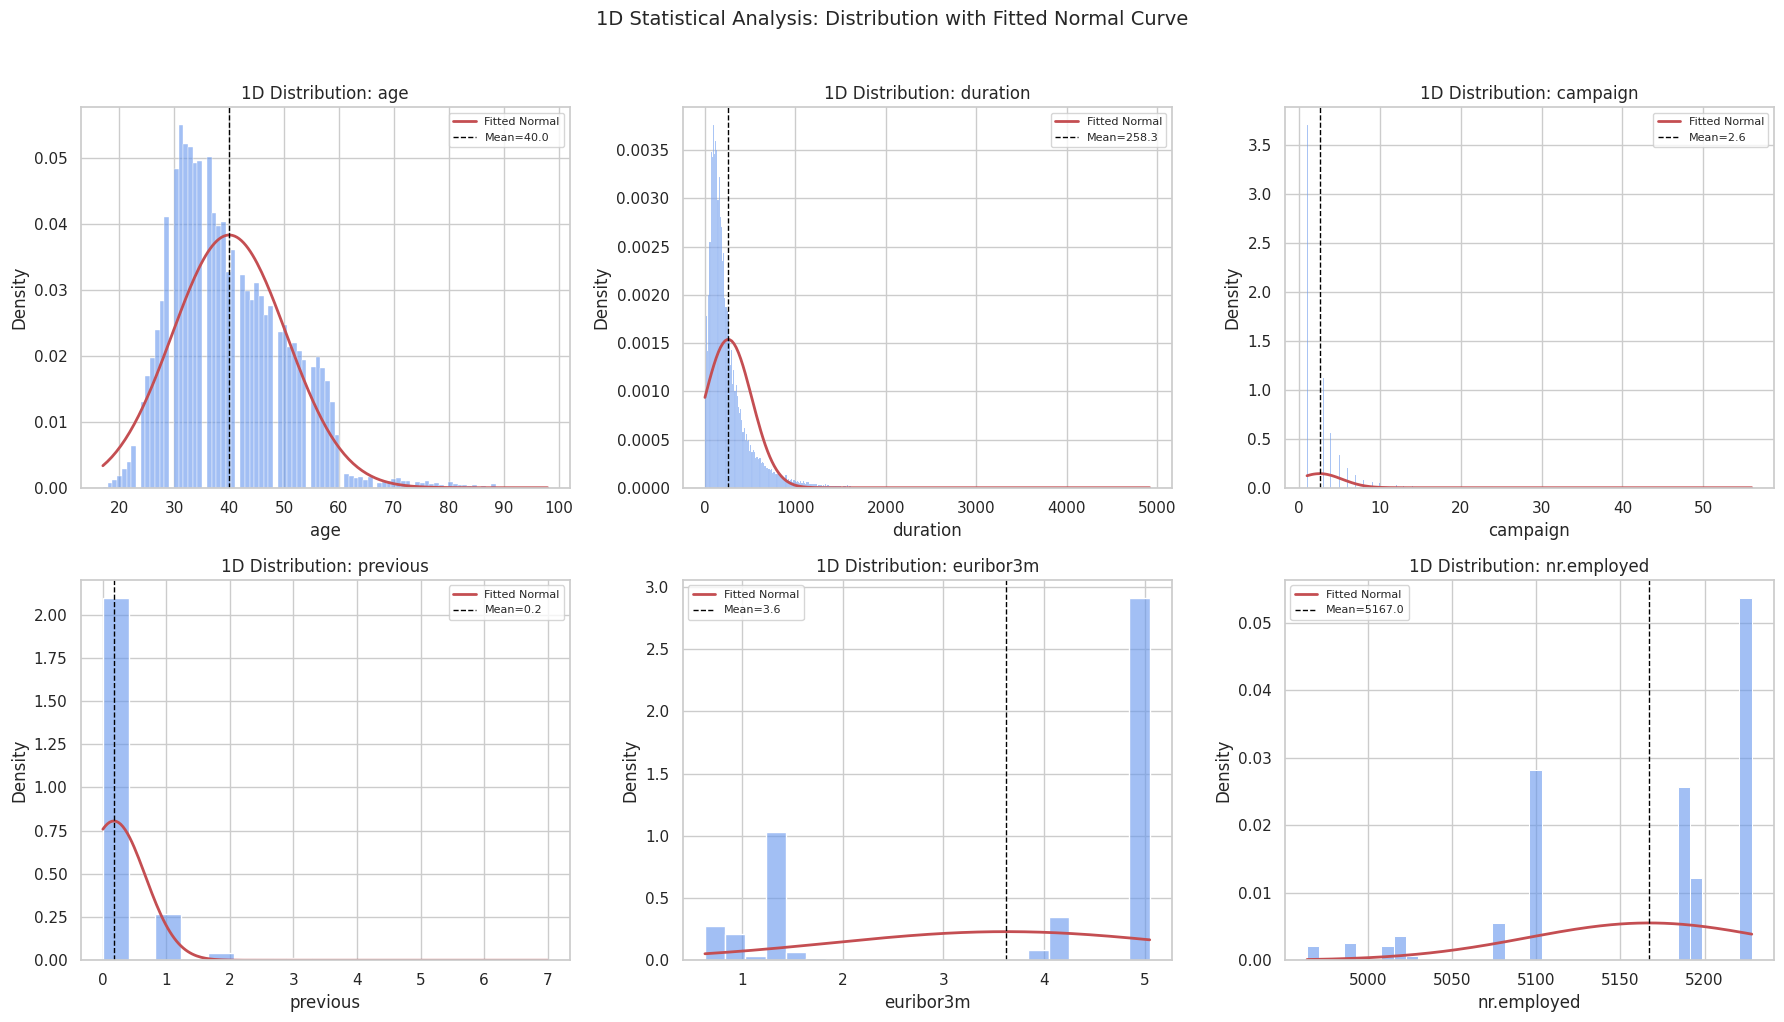

In [77]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
key_vars = ['age', 'duration', 'campaign', 'previous', 'euribor3m', 'nr.employed']

for ax, col in zip(axes.flatten(), key_vars):
    data = df[col].dropna()
    sns.histplot(data, kde=False, stat='density', color='cornflowerblue', ax=ax, alpha=0.6)
    mu, sigma = data.mean(), data.std()
    x = np.linspace(data.min(), data.max(), 200)
    ax.plot(x, stats.norm.pdf(x, mu, sigma), 'r-', linewidth=2, label='Fitted Normal')
    ax.axvline(mu, color='black', linestyle='--', linewidth=1, label=f'Mean={mu:.1f}')
    ax.set_title(f'1D Distribution: {col}')
    ax.legend(fontsize=8)

plt.suptitle('1D Statistical Analysis: Distribution with Fitted Normal Curve', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 2. Two-Dimensional (2D) Statistical Analysis

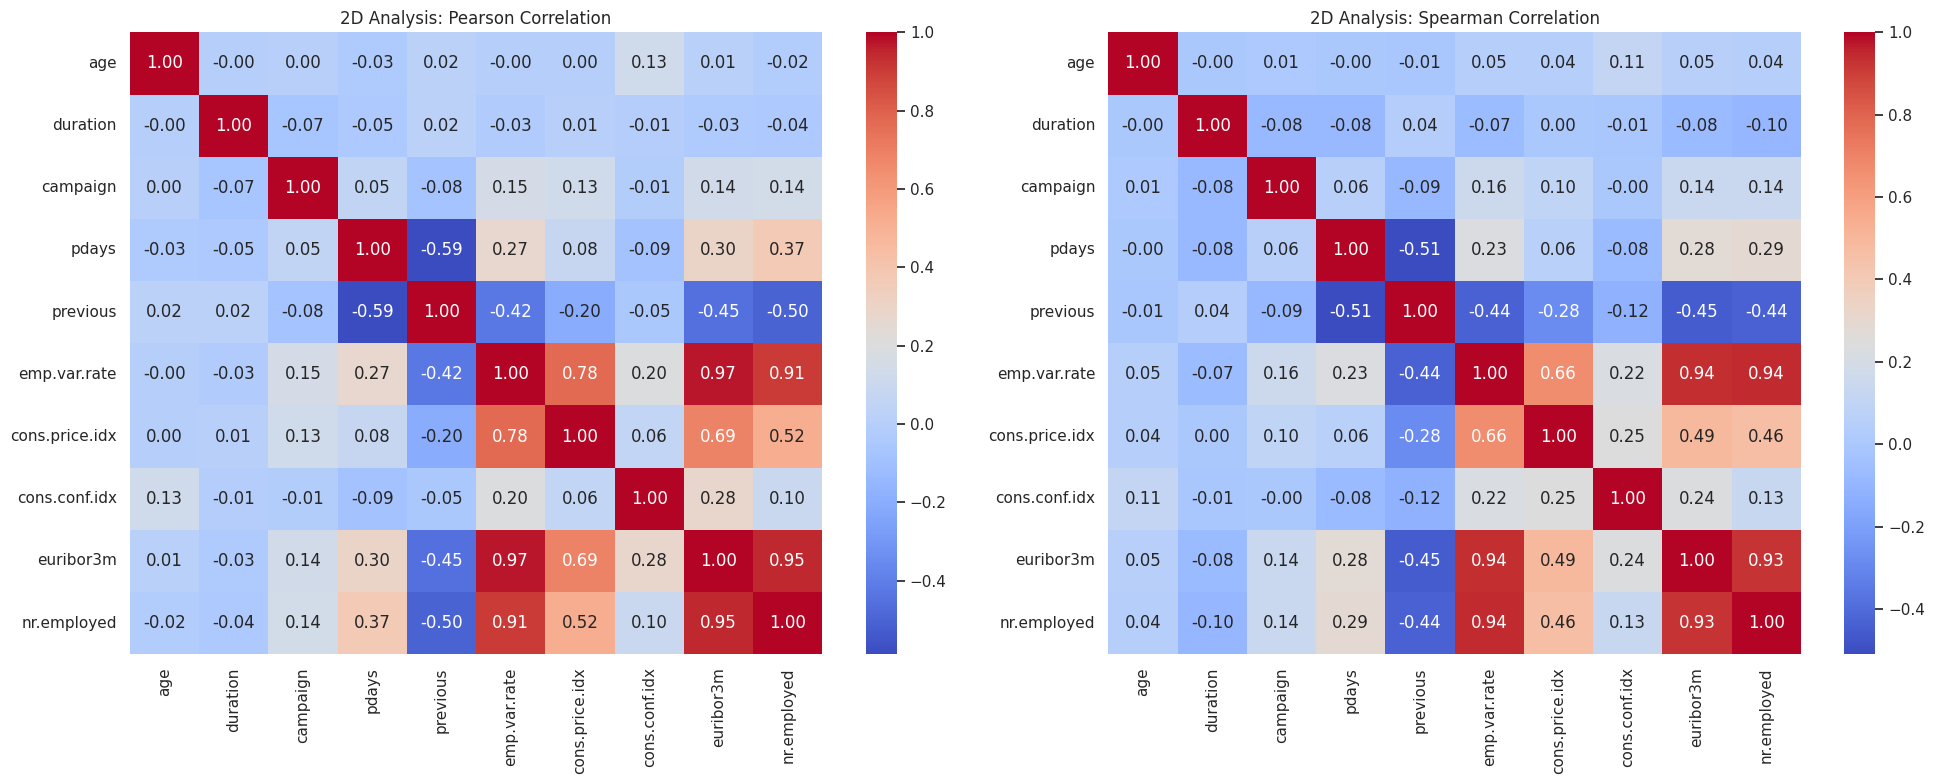

In [78]:
pearson_corr = df[numeric_cols].corr(method='pearson')
spearman_corr = df[numeric_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0])
axes[0].set_title('2D Analysis: Pearson Correlation')
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('2D Analysis: Spearman Correlation')
plt.tight_layout()
plt.show()

In [79]:
cov_matrix = df[['age', 'duration', 'campaign', 'previous', 'euribor3m']].cov().round(2)
display(cov_matrix)

,age,duration,campaign,previous,euribor3m
age,108.59,-2.17,0.13,0.13,0.20
duration,-2.17,67241.19,-51.57,2.64,-14.77
campaign,0.13,-51.57,7.67,-0.11,0.65
previous,0.13,2.64,-0.11,0.25,-0.39
euribor3m,0.20,-14.77,0.65,-0.39,3.01


In [80]:
groups = [g['duration'].dropna().values for _, g in df.groupby('education')]
f_stat, p_val = stats.f_oneway(*groups)
print(f"ANOVA (Call Duration vs Education): F-statistic = {f_stat:.3f}, p-value = {p_val:.4g}")
print("=> Significant difference across education levels" if p_val < 0.05 else "=> No significant difference")

contingency = pd.crosstab(df['job'], df['y'])
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print(f"\nChi-Square Test (Job vs y): chi2 = {chi2:.3f}, p-value = {p_chi:.4g}, dof = {dof}")
print("=> Significant association" if p_chi < 0.05 else "=> No significant association")

r, p_corr = stats.pearsonr(df['euribor3m'], df['nr.employed'])
print(f"\nPearson correlation (euribor3m vs nr.employed): r = {r:.3f}, p-value = {p_corr:.4g}")

ANOVA (Call Duration vs Education): F-statistic = 1.926, p-value = 0.07259
=> No significant difference

Chi-Square Test (Job vs y): chi2 = 960.678, p-value = 5.507e-200, dof = 10
=> Significant association

Pearson correlation (euribor3m vs nr.employed): r = 0.945, p-value = 0


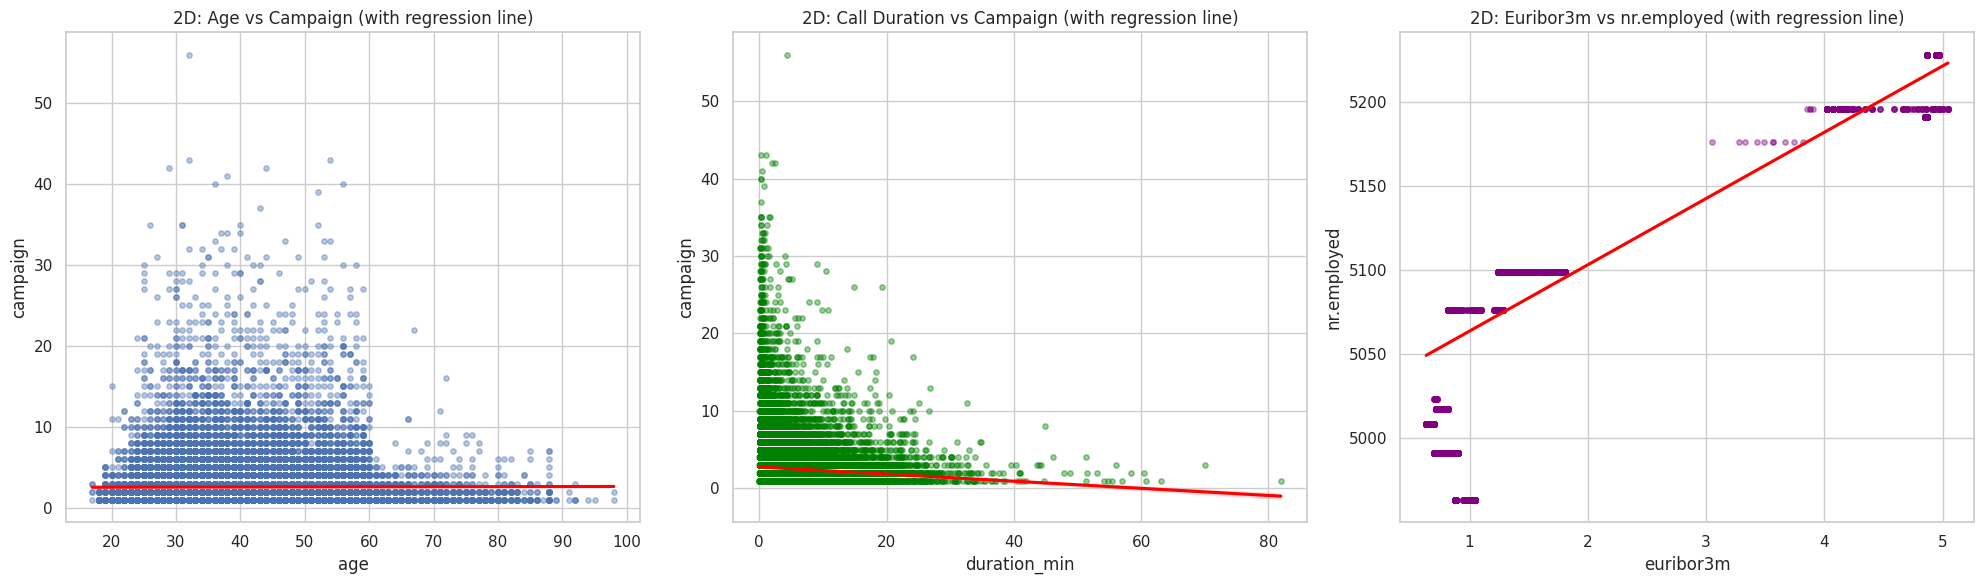

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.regplot(data=df, x='age', y='campaign', ax=axes[0], scatter_kws={'alpha':0.4, 's':15}, line_kws={'color':'red'})
axes[0].set_title('2D: Age vs Campaign (with regression line)')

sns.regplot(data=df, x='duration_min', y='campaign', ax=axes[1], scatter_kws={'alpha':0.4, 's':15, 'color':'green'}, line_kws={'color':'red'})
axes[1].set_title('2D: Call Duration vs Campaign (with regression line)')

sns.regplot(data=df, x='euribor3m', y='nr.employed', ax=axes[2], scatter_kws={'alpha':0.4, 's':15, 'color':'purple'}, line_kws={'color':'red'})
axes[2].set_title('2D: Euribor3m vs nr.employed (with regression line)')

plt.tight_layout()
plt.show()

## 3. Three-Dimensional (3D) Statistical Analysis

In [82]:
three_way = df.groupby(['marital', 'education'])['duration'].agg(['mean', 'median', 'std', 'count']).round(2)
display(three_way)

mean  median     std  count
marital  education                                         
divorced basic.4y             258.73   188.0  230.68    489
         basic.6y             278.11   199.5  253.47    182
         basic.9y             256.70   182.0  244.38    565
         high.school          256.96   178.0  266.36   1192
         illiterate           137.00   137.0   12.73      2
         professional.course  243.56   169.0  225.85    657
         university.degree    250.45   180.0  251.60   1524
married  basic.4y             265.95   185.0  267.05   3233
         basic.6y             259.01   178.0  265.95   1772
         basic.9y             262.15   183.0  262.17   4164
         high.school          255.86   179.0  253.76   5171
         illiterate           296.60   129.0  328.87     15
         professional.course  254.93   179.0  266.88   3161
         university.degree    253.56   174.0  251.86   7483
single   basic.4y             263.65   184.0  263.15    453
         basic.6y             285.88   195.0  306.77    337
         basic.9y             260.54   185.0  244.12   1316
         high.school          270.81   190.0  273.50   3149
         illiterate           259.00   259.0     NaN      1
         professional.course  251.47   170.0  280.83   1422
         university.degree    256.93   177.5  254.46   4886

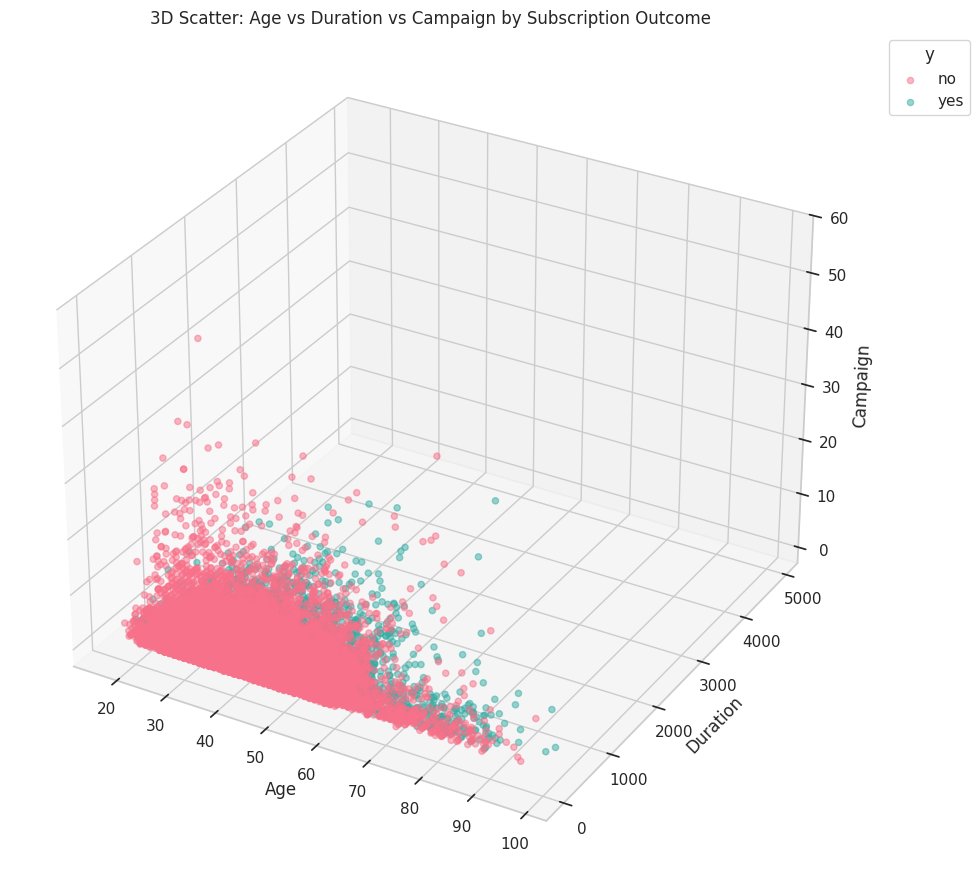

In [83]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

outcomes = df['y'].unique()
palette = sns.color_palette('husl', len(outcomes))

for outcome, color in zip(outcomes, palette):
    subset = df[df['y'] == outcome]
    ax.scatter(subset['age'], subset['duration'], subset['campaign'], label=outcome, color=color, alpha=0.5, s=20)

ax.set_xlabel('Age')
ax.set_ylabel('Duration')
ax.set_zlabel('Campaign')
ax.set_title('3D Scatter: Age vs Duration vs Campaign by Subscription Outcome')
ax.legend(title='y', bbox_to_anchor=(1.15, 1))
plt.tight_layout()
plt.show()

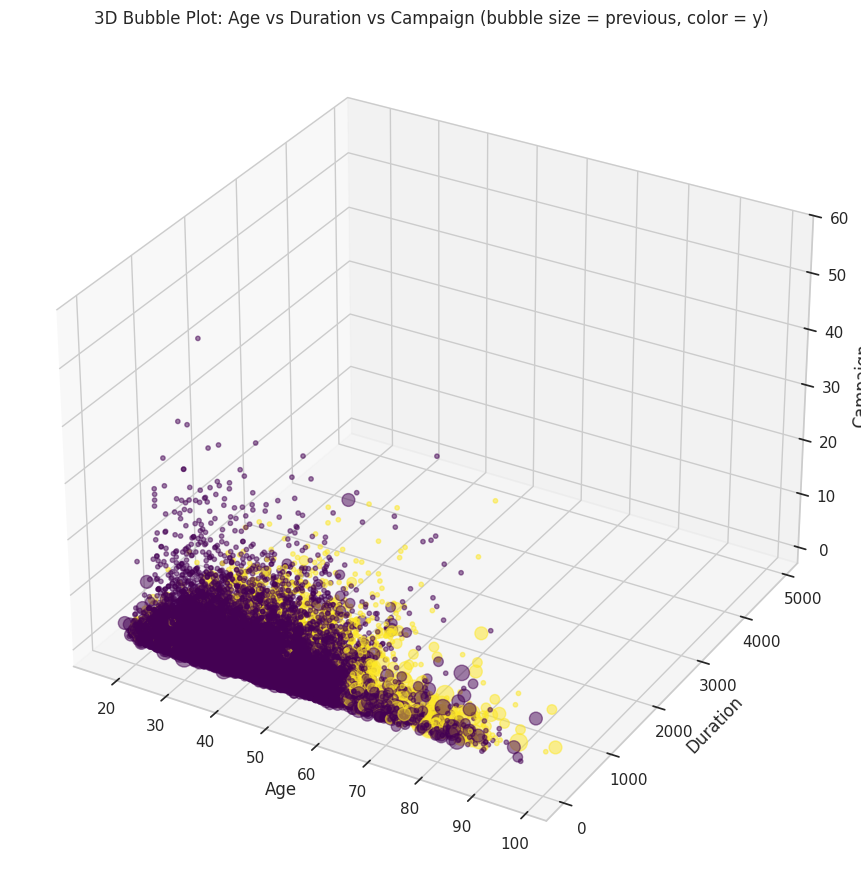

In [84]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

sizes = (df['previous'] / (df['previous'].max() + 1)) * 300 + 10
sc = ax.scatter(df['age'], df['duration'], df['campaign'], c=df['y_Encoded'], cmap='viridis', s=sizes, alpha=0.5)

ax.set_xlabel('Age')
ax.set_ylabel('Duration')
ax.set_zlabel('Campaign')
ax.set_title('3D Bubble Plot: Age vs Duration vs Campaign (bubble size = previous, color = y)')
legend1 = ax.legend(*sc.legend_elements(), title="y (encoded)", bbox_to_anchor=(1.2, 1))
ax.add_artist(legend1)
plt.tight_layout()
plt.show()

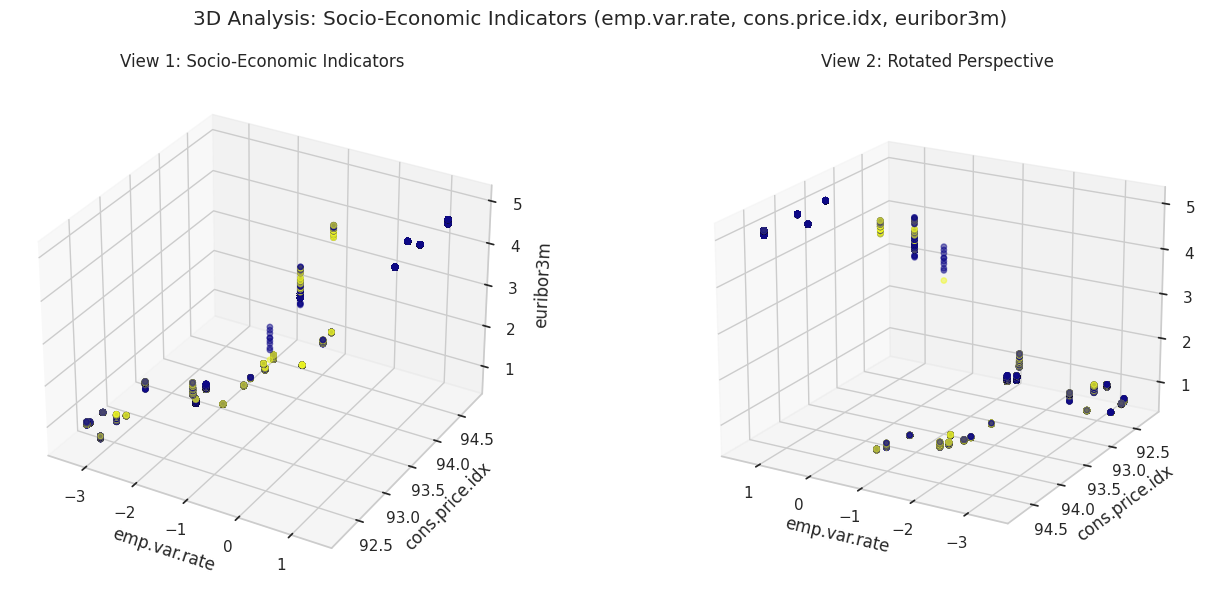

In [85]:
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(df['emp.var.rate'], df['cons.price.idx'], df['euribor3m'], c=df['y_Encoded'], cmap='plasma', alpha=0.5, s=15)
ax1.set_xlabel('emp.var.rate'); ax1.set_ylabel('cons.price.idx'); ax1.set_zlabel('euribor3m')
ax1.set_title('View 1: Socio-Economic Indicators')

ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(df['emp.var.rate'], df['cons.price.idx'], df['euribor3m'], c=df['y_Encoded'], cmap='plasma', alpha=0.5, s=15)
ax2.view_init(elev=20, azim=120)
ax2.set_xlabel('emp.var.rate'); ax2.set_ylabel('cons.price.idx'); ax2.set_zlabel('euribor3m')
ax2.set_title('View 2: Rotated Perspective')

plt.suptitle('3D Analysis: Socio-Economic Indicators (emp.var.rate, cons.price.idx, euribor3m)')
plt.tight_layout()
plt.show()

## 4. K-Means Clustering

In [86]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

cluster_features = ['age', 'duration', 'campaign', 'pdays', 'previous',
                     'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

X = df[cluster_features].copy()
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Features used for clustering: {cluster_features}")
print(f"Scaled data shape: {X_scaled.shape}")

Features used for clustering: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Scaled data shape: (41174, 10)


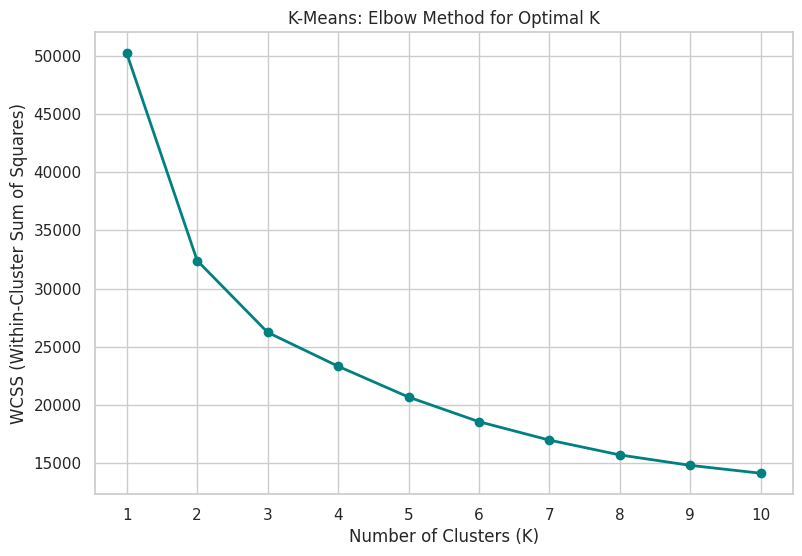

In [87]:
X_sample_idx = np.random.RandomState(42).choice(len(X_scaled), size=5000, replace=False)
X_scaled_sample = X_scaled[X_sample_idx]

wcss = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X_scaled_sample)
    wcss.append(km.inertia_)

plt.figure(figsize=(9, 6))
plt.plot(K_range, wcss, marker='o', linewidth=2, color='teal')
plt.title('K-Means: Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

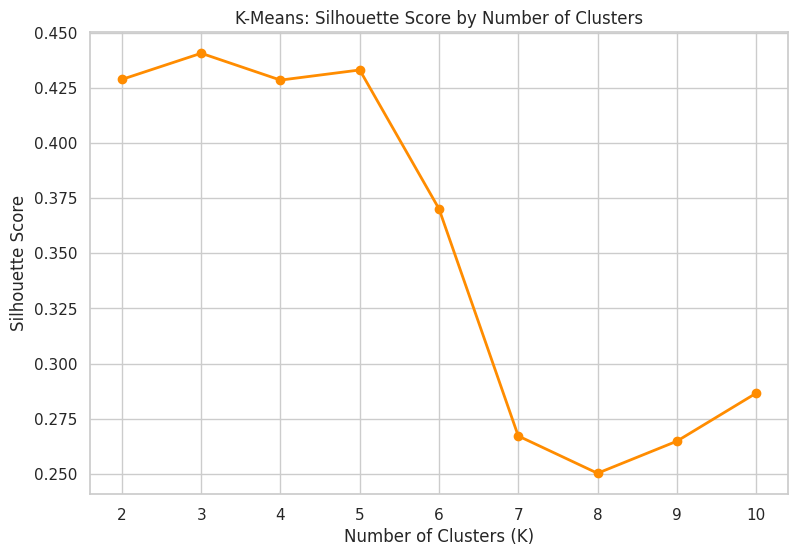

Optimal K (highest silhouette score) = 3


In [88]:
sil_scores = []
K_range_sil = range(2, 11)
for k in K_range_sil:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled_sample)
    sil_scores.append(silhouette_score(X_scaled_sample, labels))

plt.figure(figsize=(9, 6))
plt.plot(list(K_range_sil), sil_scores, marker='o', linewidth=2, color='darkorange')
plt.title('K-Means: Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(K_range_sil))
plt.grid(True)
plt.show()

optimal_k = list(K_range_sil)[np.argmax(sil_scores)]
print(f"Optimal K (highest silhouette score) = {optimal_k}")

In [89]:
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"--- K-Means Clustering with K={optimal_k} ---")
print(df['KMeans_Cluster'].value_counts().sort_index())

--- K-Means Clustering with K=3 ---
KMeans_Cluster
0    11999
1    27635
2     1540
Name: count, dtype: int64


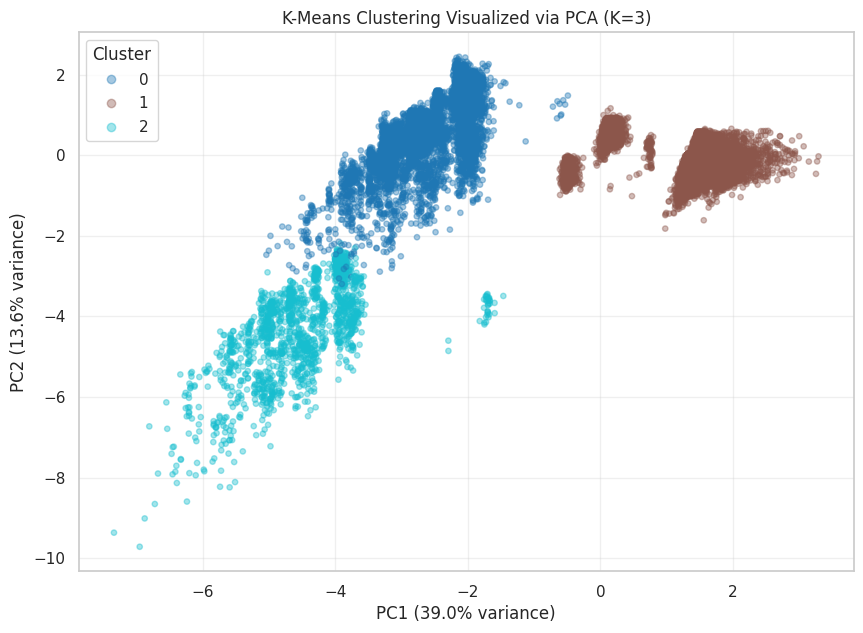

In [90]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['KMeans_Cluster'], cmap='tab10', alpha=0.4, s=15)
plt.title(f'K-Means Clustering Visualized via PCA (K={optimal_k})')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

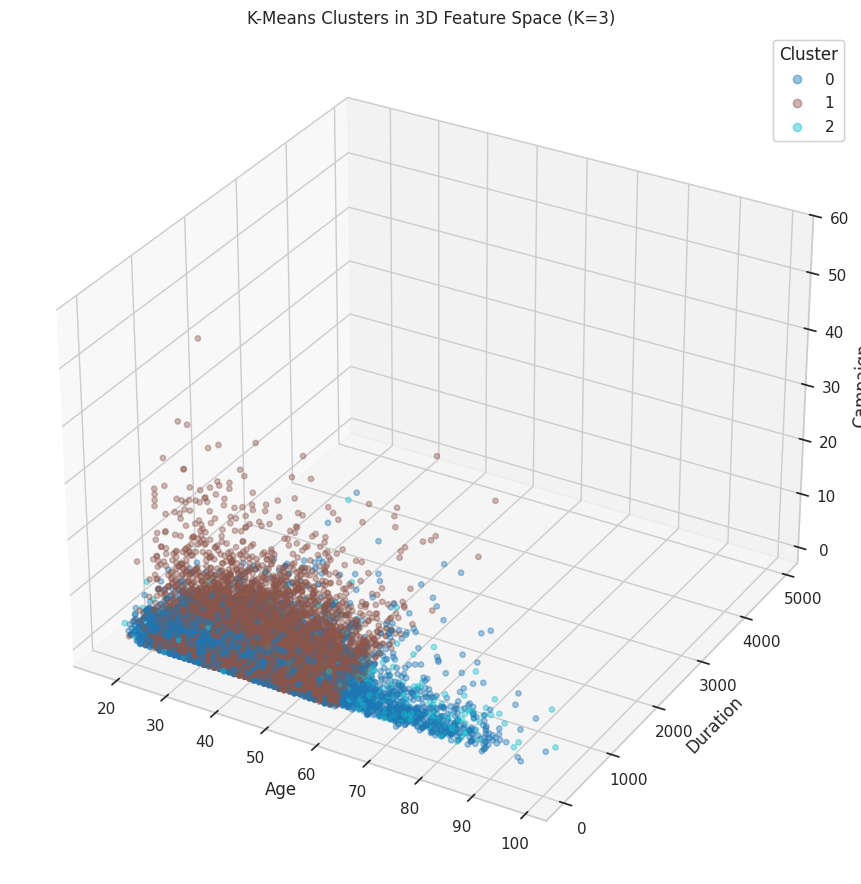

In [91]:
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(df['age'], df['duration'], df['campaign'], c=df['KMeans_Cluster'], cmap='tab10', alpha=0.4, s=15)
ax.set_xlabel('Age'); ax.set_ylabel('Duration'); ax.set_zlabel('Campaign')
ax.set_title(f'K-Means Clusters in 3D Feature Space (K={optimal_k})')
legend1 = ax.legend(*sc.legend_elements(), title='Cluster')
ax.add_artist(legend1)
plt.tight_layout()
plt.show()

In [92]:
cluster_profile = df.groupby('KMeans_Cluster')[cluster_features].mean().round(2)
display(cluster_profile)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
KMeans_Cluster,,,,,,,,,,
0,39.39,263.66,2.12,999.00,0.32,-2.03,92.99,-43.19,1.20,5077.98
1,40.19,252.44,2.80,999.00,0.03,1.12,93.84,-39.46,4.82,5213.42
2,41.91,322.33,1.83,22.13,1.69,-2.09,93.35,-38.33,0.98,5028.54


## 5. Hierarchical Clustering

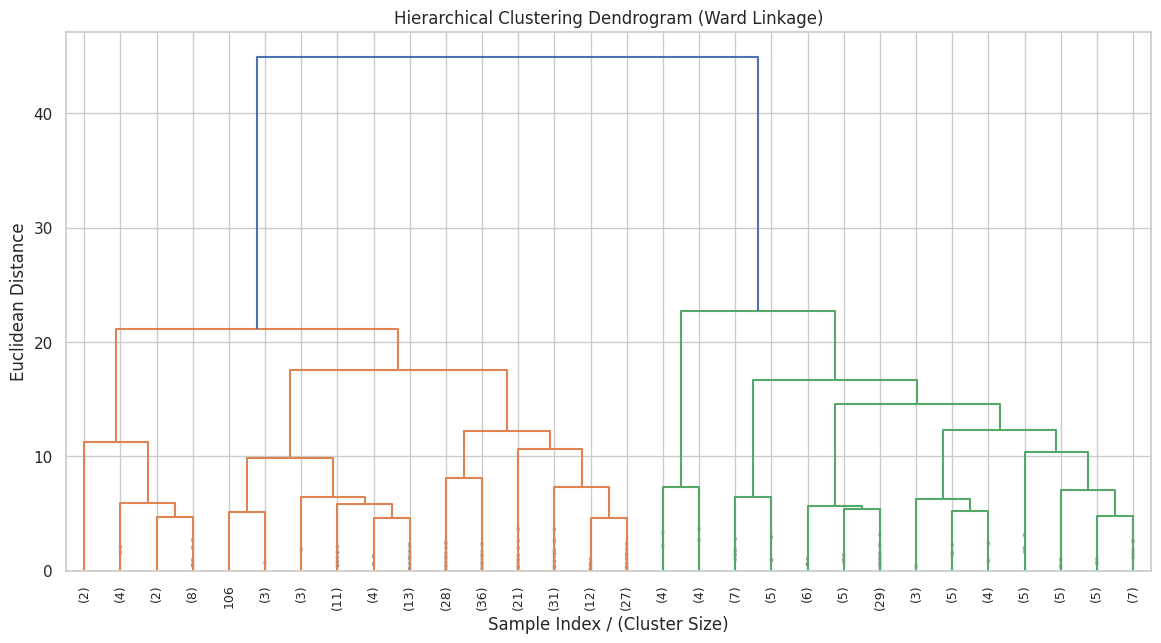

In [93]:
from scipy.cluster.hierarchy import dendrogram, linkage

hc_sample_idx = np.random.RandomState(42).choice(len(X_scaled), size=300, replace=False)
X_hc_sample = X_scaled[hc_sample_idx]

linked = linkage(X_hc_sample, method='ward')

plt.figure(figsize=(14, 7))
dendrogram(linked, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Sample Index / (Cluster Size)')
plt.ylabel('Euclidean Distance')
plt.show()

In [94]:
hc = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
df.loc[hc_sample_idx, 'Hierarchical_Cluster'] = hc.fit_predict(X_hc_sample)

print(f"--- Hierarchical Clustering with K={optimal_k} (on {len(hc_sample_idx)}-point sample) ---")
print(df.loc[hc_sample_idx, 'Hierarchical_Cluster'].value_counts().sort_index())

hc_sil = silhouette_score(X_hc_sample, df.loc[hc_sample_idx, 'Hierarchical_Cluster'])
km_sil_sample = silhouette_score(X_hc_sample, df.loc[hc_sample_idx, 'KMeans_Cluster'])
print(f"\nSilhouette Score - K-Means (same sample): {km_sil_sample:.3f}")
print(f"Silhouette Score - Hierarchical: {hc_sil:.3f}")

--- Hierarchical Clustering with K=3 (on 300-point sample) ---
Hierarchical_Cluster
0.0    206
1.0     86
2.0      8
Name: count, dtype: int64

Silhouette Score - K-Means (same sample): 0.393
Silhouette Score - Hierarchical: 0.428


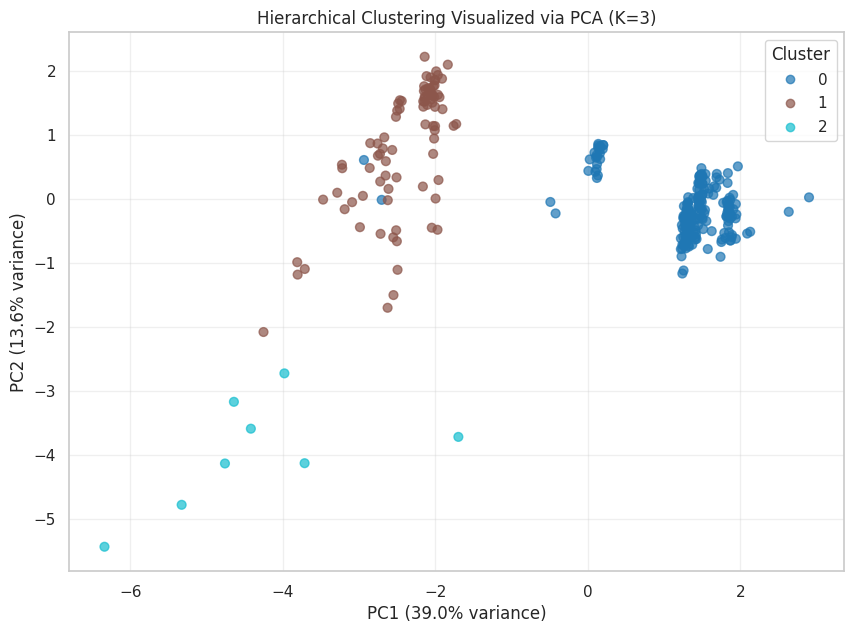

In [95]:
X_pca_sample = pca.transform(X_hc_sample)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca_sample[:, 0], X_pca_sample[:, 1], c=df.loc[hc_sample_idx, 'Hierarchical_Cluster'], cmap='tab10', alpha=0.7, s=40)
plt.title(f'Hierarchical Clustering Visualized via PCA (K={optimal_k})')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

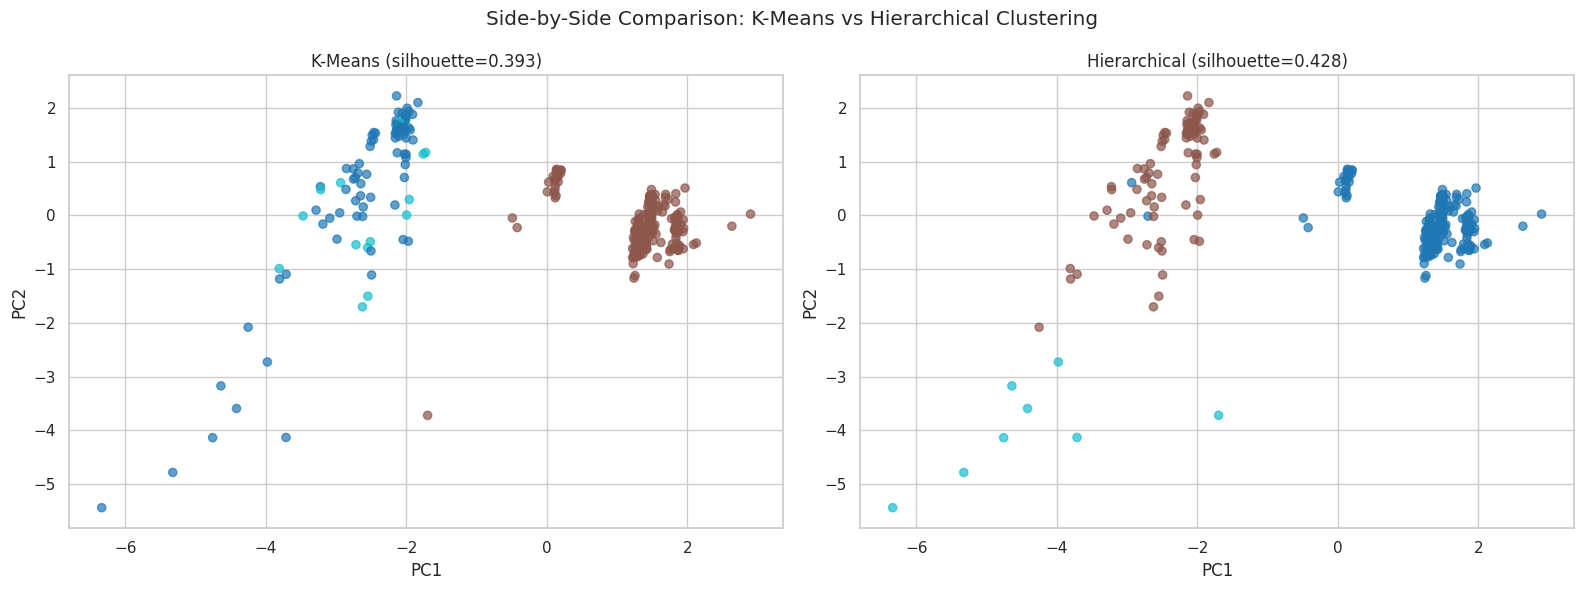

Hierarchical_Cluster,0.0,1.0,2.0
KMeans_Cluster,,,
0,1,73,7
1,204,0,1
2,1,13,0


y,no,yes
KMeans_Cluster,,
0,9668,2331
1,26300,1335
2,567,973


In [96]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(X_pca_sample[:, 0], X_pca_sample[:, 1], c=df.loc[hc_sample_idx, 'KMeans_Cluster'], cmap='tab10', alpha=0.7, s=35)
axes[0].set_title(f'K-Means (silhouette={km_sil_sample:.3f})')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')

axes[1].scatter(X_pca_sample[:, 0], X_pca_sample[:, 1], c=df.loc[hc_sample_idx, 'Hierarchical_Cluster'], cmap='tab10', alpha=0.7, s=35)
axes[1].set_title(f'Hierarchical (silhouette={hc_sil:.3f})')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')

plt.suptitle('Side-by-Side Comparison: K-Means vs Hierarchical Clustering')
plt.tight_layout()
plt.show()

display(pd.crosstab(df.loc[hc_sample_idx, 'KMeans_Cluster'], df.loc[hc_sample_idx, 'Hierarchical_Cluster']))
display(pd.crosstab(df['KMeans_Cluster'], df['y']))

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [98]:
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/bank-full.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Number of rows: 41188
Number of columns: 21

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Missing values:
age               0
job               0
marital           0
education         0
default           0
housin

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Target variable distribution:
y
no     36548
yes     4640
Name: count, dtype: int64


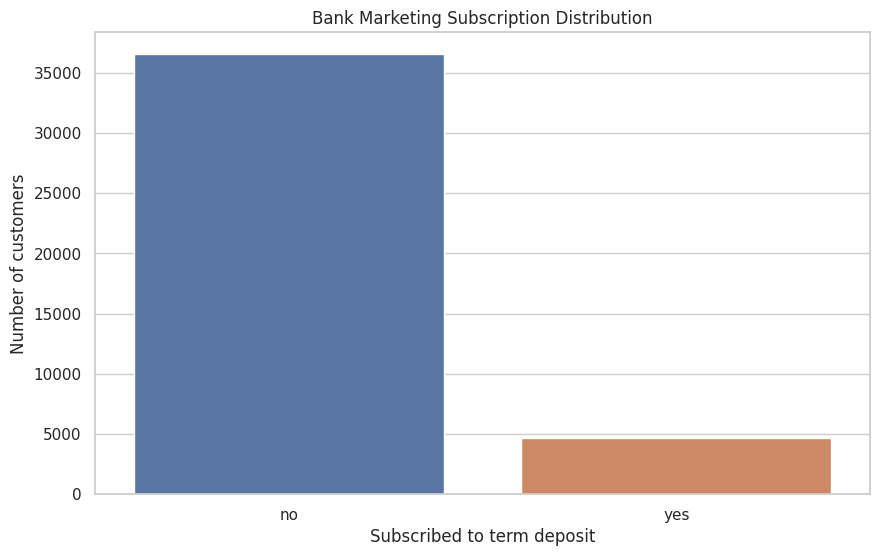

In [99]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nTarget variable distribution:")
print(df["y"].value_counts())

sns.countplot(data=df, x="y", hue="y", legend=False)
plt.title("Bank Marketing Subscription Distribution")
plt.xlabel("Subscribed to term deposit")
plt.ylabel("Number of customers")
plt.show()

In [100]:
X = df.drop(columns=["y"])
y = df["y"]

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)

# Standardize numerical features and encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols)
    ],
    remainder="drop"
)

X_processed = preprocessor.fit_transform(X)

# Retrieve names of the transformed features
feature_names = preprocessor.get_feature_names_out()

print("\nOriginal feature shape:", X.shape)
print("Processed feature shape:", X_processed.shape)
print("Preprocessing completed successfully!")

Numerical columns: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Original feature shape: (41188, 20)
Processed feature shape: (41188, 63)
Preprocessing completed successfully!


In [101]:
# Fit PCA with all available components
pca = PCA()
X_pca = pca.fit_transform(X_processed)

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_df = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

print("PCA completed successfully!")
print("Number of principal components:", X_pca.shape[1])

display(variance_df.head(10).round(3))

# Number of components needed to retain at least 80% variance
n_components_80 = np.argmax(cumulative_variance >= 0.80) + 1

print(
    f"Components required to explain at least 80% of variance: "
    f"{n_components_80}"
)

PCA completed successfully!
Number of principal components: 63


,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,26.303,26.303
1,PC2,9.168,35.471
2,PC3,7.461,42.932
3,PC4,6.747,49.678
4,PC5,6.259,55.937
5,PC6,5.691,61.629
6,PC7,4.467,66.095
7,PC8,3.067,69.162
8,PC9,2.979,72.141
9,PC10,2.595,74.736


Components required to explain at least 80% of variance: 13


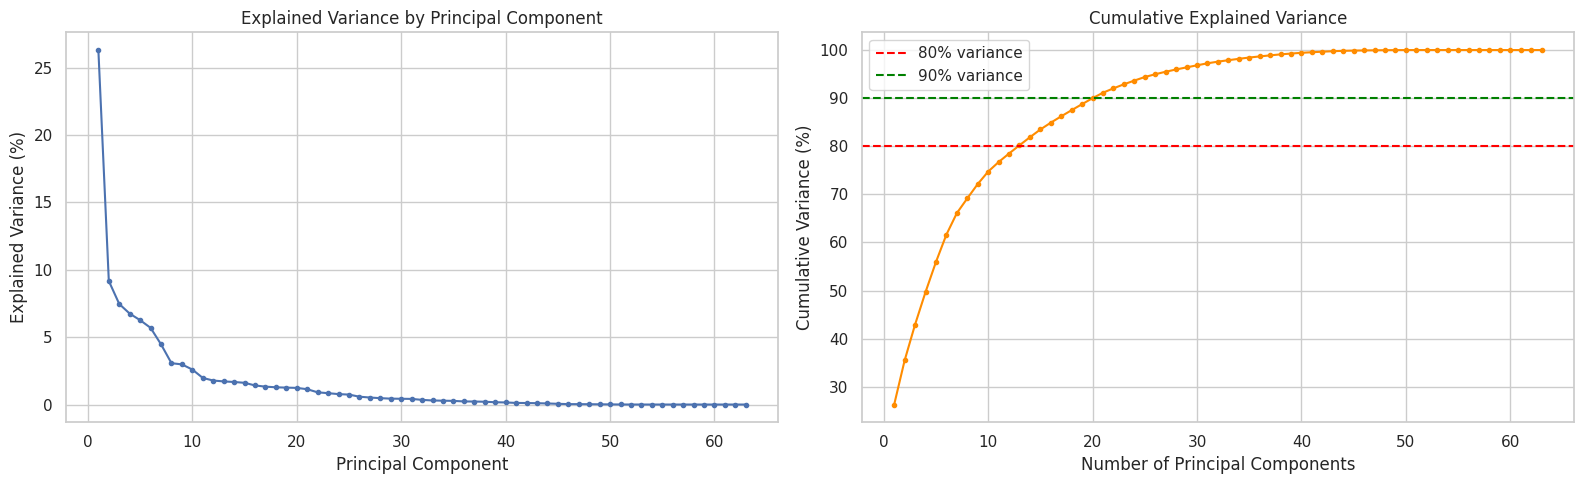

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Individual explained variance
axes[0].plot(
    range(1, len(explained_variance) + 1),
    explained_variance * 100,
    marker="o",
    markersize=3
)
axes[0].set_title("Explained Variance by Principal Component")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance (%)")
axes[0].grid(True)

# Cumulative explained variance
axes[1].plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o",
    markersize=3,
    color="darkorange"
)
axes[1].axhline(80, color="red", linestyle="--", label="80% variance")
axes[1].axhline(90, color="green", linestyle="--", label="90% variance")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Variance (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

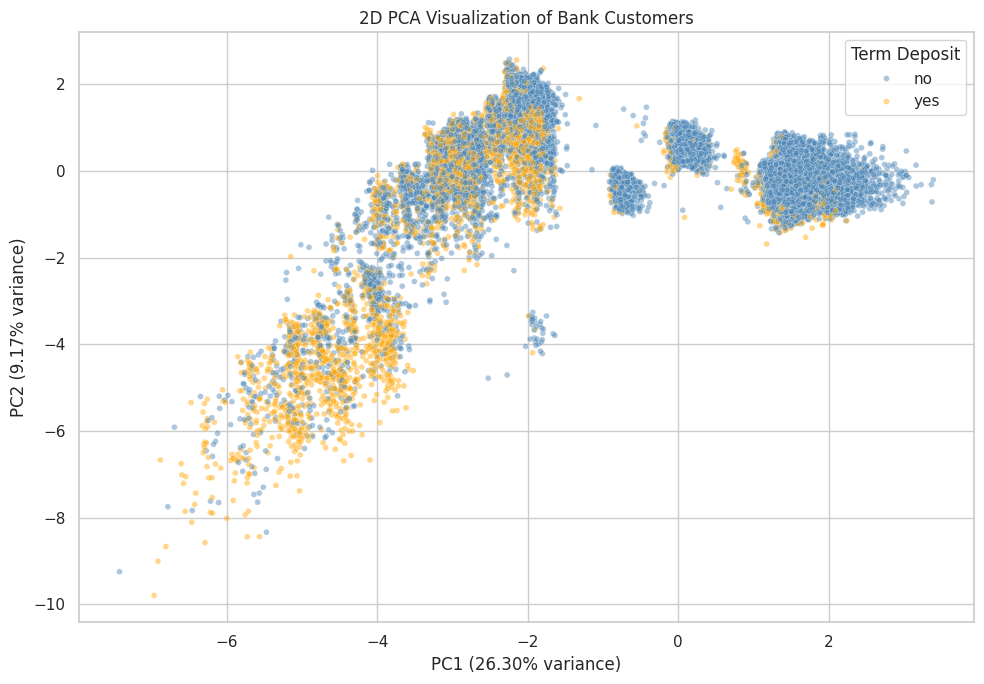

In [103]:
# Create a DataFrame containing the first two components
pca_2d = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Subscription": y.to_numpy()
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_2d,
    x="PC1",
    y="PC2",
    hue="Subscription",
    palette={"no": "steelblue", "yes": "orange"},
    alpha=0.45,
    s=18
)

plt.title("2D PCA Visualization of Bank Customers")
plt.xlabel(
    f"PC1 ({explained_variance[0] * 100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({explained_variance[1] * 100:.2f}% variance)"
)
plt.legend(title="Term Deposit")
plt.tight_layout()
plt.show()

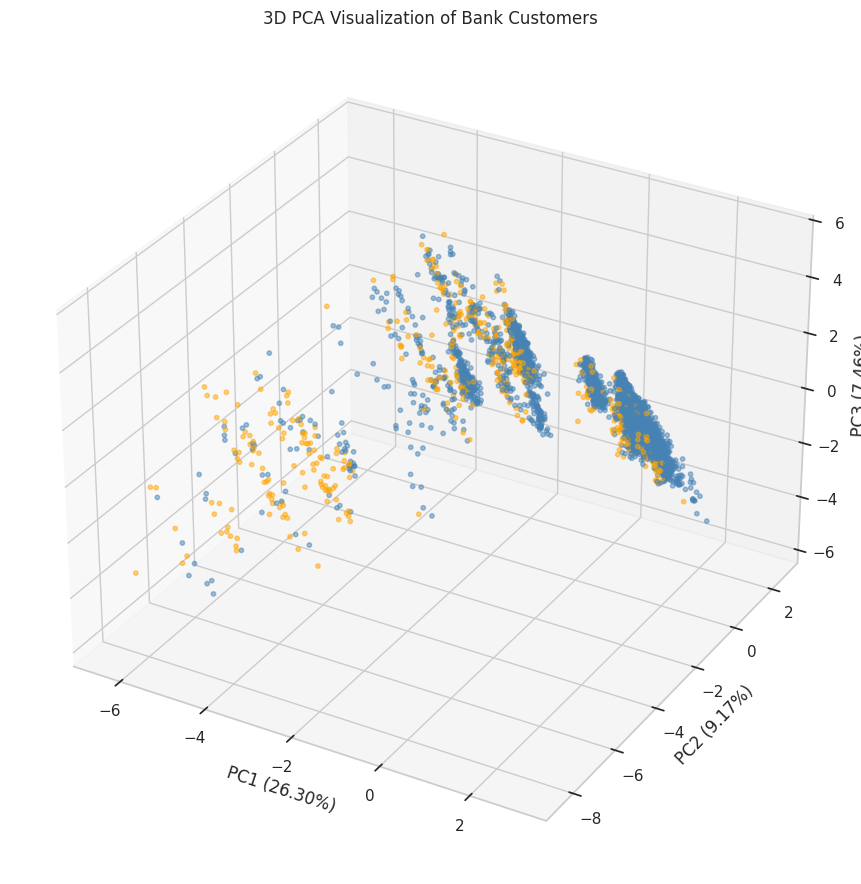

Blue = No subscription
Orange = Yes subscription


In [104]:
from mpl_toolkits.mplot3d import Axes3D

# Sample customers for faster 3D plotting
plot_df = pca_2d.join(
    pd.DataFrame({"PC3": X_pca[:, 2]}, index=pca_2d.index)
)

plot_df = plot_df.sample(
    n=min(5000, len(plot_df)),
    random_state=42
)

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

colors = plot_df["Subscription"].map({
    "no": "steelblue",
    "yes": "orange"
})

ax.scatter(
    plot_df["PC1"],
    plot_df["PC2"],
    plot_df["PC3"],
    c=colors,
    alpha=0.5,
    s=10
)

ax.set_title("3D PCA Visualization of Bank Customers")
ax.set_xlabel(f"PC1 ({explained_variance[0]*100:.2f}%)")
ax.set_ylabel(f"PC2 ({explained_variance[1]*100:.2f}%)")
ax.set_zlabel(f"PC3 ({explained_variance[2]*100:.2f}%)")

plt.tight_layout()
plt.show()

print("Blue = No subscription")
print("Orange = Yes subscription")

Top 10 features contributing to PC1:


,Absolute Loading
num__euribor3m,0.474219
num__emp.var.rate,0.471998
num__nr.employed,0.451640
num__cons.price.idx,0.362964
num__previous,0.301984
num__pdays,0.219251
cat__contact_telephone,0.113103
cat__contact_cellular,0.113103
cat__poutcome_nonexistent,0.106524
num__cons.conf.idx,0.103478


Top 10 features contributing to PC2:


,Absolute Loading
num__pdays,0.597829
num__previous,0.462823
num__cons.conf.idx,0.419444
num__age,0.275629
num__cons.price.idx,0.273840
num__emp.var.rate,0.143679
num__euribor3m,0.130233
cat__poutcome_nonexistent,0.116694
cat__poutcome_success,0.100127
cat__contact_telephone,0.094763


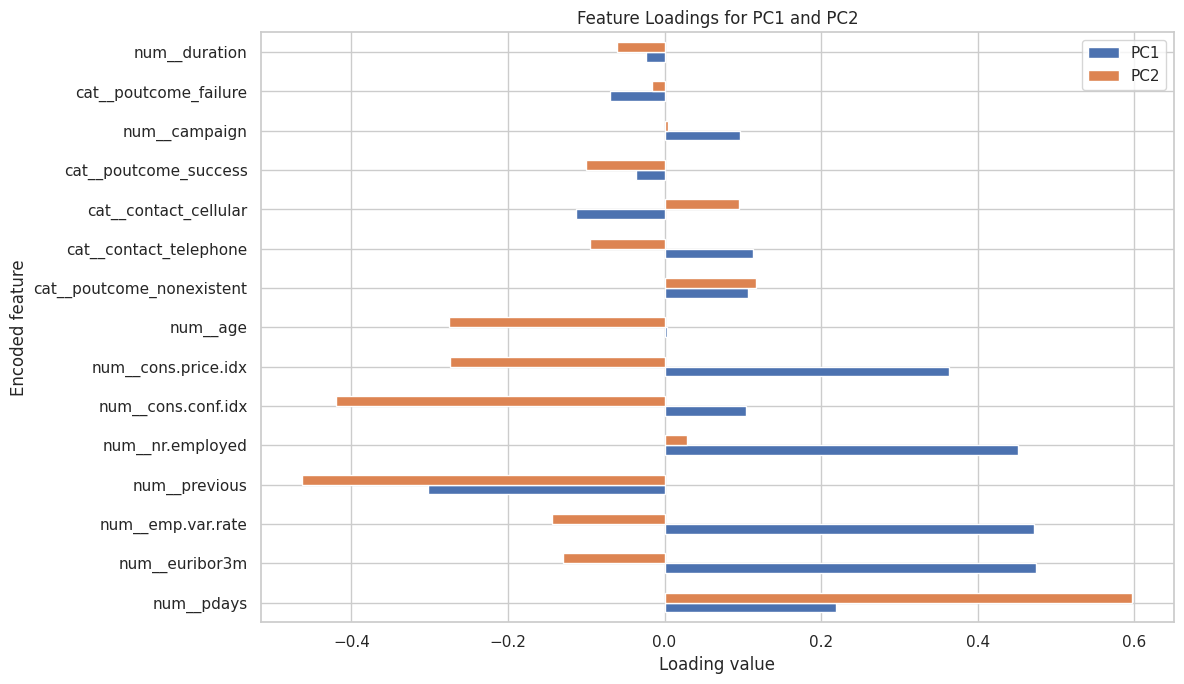

In [105]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_names,
    columns=[
        f"PC{i+1}" for i in range(pca.n_components_)
    ]
)

print("Top 10 features contributing to PC1:")
display(
    loadings["PC1"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Absolute Loading")
)

print("Top 10 features contributing to PC2:")
display(
    loadings["PC2"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Absolute Loading")
)

# Plot the most influential features
top_features = (
    loadings[["PC1", "PC2"]]
    .abs()
    .max(axis=1)
    .sort_values(ascending=False)
    .head(15)
    .index
)

loadings.loc[top_features, ["PC1", "PC2"]].plot(
    kind="barh",
    figsize=(12, 7)
)

plt.title("Feature Loadings for PC1 and PC2")
plt.xlabel("Loading value")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

In [106]:
print("=" * 50)
print("PCA ANALYSIS SUMMARY")
print("=" * 50)

print("Total customers:", len(df))
print("Original input features:", X.shape[1])
print("Encoded features:", X_processed.shape[1])

print(f"\nPC1 variance explained: {explained_variance[0]*100:.2f}%")
print(f"PC2 variance explained: {explained_variance[1]*100:.2f}%")
print(f"PC3 variance explained: {explained_variance[2]*100:.2f}%")

print(
    f"\nTotal variance explained by first 2 PCs: "
    f"{cumulative_variance[1]*100:.2f}%"
)
print(
    f"Total variance explained by first 3 PCs: "
    f"{cumulative_variance[2]*100:.2f}%"
)

print(
    f"Components needed for 80% variance: {n_components_80}"
)

print("\nPCA analysis completed successfully!")

PCA ANALYSIS SUMMARY
Total customers: 41188
Original input features: 20
Encoded features: 63

PC1 variance explained: 26.30%
PC2 variance explained: 9.17%
PC3 variance explained: 7.46%

Total variance explained by first 2 PCs: 35.47%
Total variance explained by first 3 PCs: 42.93%
Components needed for 80% variance: 13

PCA analysis completed successfully!
